In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
os.makedirs("../reports", exist_ok=True)

df = pd.read_csv("../data/Pakistani_Diabetes_Dataset.csv")
df.columns = df.columns.str.strip()

bad_bmi = (df.BMI < 12) | (df.BMI > 60)
print("Impossible BMI rows removed:", bad_bmi.sum())
df = df[~bad_bmi]
print("Duplicate rows removed:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape, df.Outcome.value_counts().to_dict())

Impossible BMI rows removed: 3
Duplicate rows removed: 2
(907, 19) {1: 486, 0: 421}


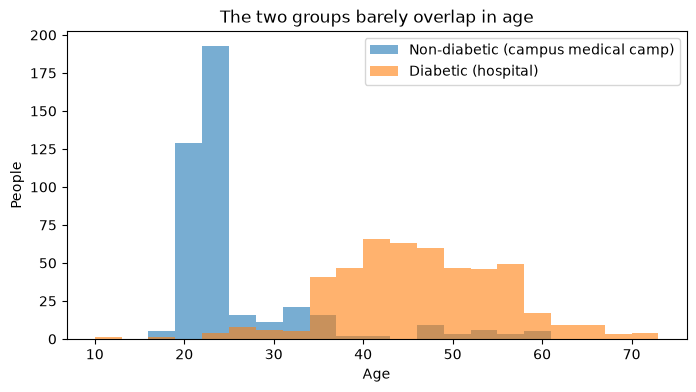

Outcome      0    1
age_group          
(0, 20]     51    2
(20, 30]   303   18
(30, 40]    41  120
(40, 50]    12  200
(50, 60]    14  121
(60, 100]    0   25


In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = range(10, 75, 3)
ax.hist(df[df.Outcome == 0].Age, bins=bins, alpha=.6, label="Non-diabetic (campus medical camp)")
ax.hist(df[df.Outcome == 1].Age, bins=bins, alpha=.6, label="Diabetic (hospital)")
ax.set_xlabel("Age"); ax.set_ylabel("People"); ax.legend()
ax.set_title("The two groups barely overlap in age")
plt.savefig("../reports/age_overlap.png", dpi=150, bbox_inches="tight"); plt.show()

df["age_group"] = pd.cut(df["Age"], [0, 20, 30, 40, 50, 60, 100])
print(pd.crosstab(df["age_group"], df["Outcome"]))
df = df.drop(columns="age_group")

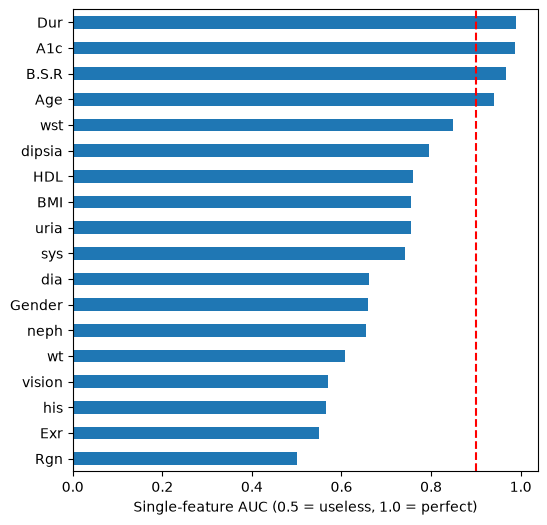

In [3]:
feats = [c for c in df.columns if c != "Outcome"]
single = pd.Series({c: roc_auc_score(df.Outcome, df[c]) for c in feats})
single = single.apply(lambda a: max(a, 1 - a)).sort_values()
single.plot.barh(figsize=(6, 6))
plt.axvline(0.9, color="red", ls="--")
plt.xlabel("Single-feature AUC (0.5 = useless, 1.0 = perfect)")
plt.savefig("../reports/single_feature_auc.png", dpi=150, bbox_inches="tight"); plt.show()

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

def evaluate(data, features, name):
    X, y = data[features], data["Outcome"]
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    auc = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    acc = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    return {"experiment": name, "n": len(data), "n_features": len(features),
            "AUC": round(auc.mean(), 3), "AUC_std": round(auc.std(), 3),
            "accuracy": round(acc.mean(), 3)}

all_features = [c for c in df.columns if c != "Outcome"]
# diagnostic tests, symptoms, complications, and duration of diabetes
leaky = ["A1c", "B.S.R", "Dur", "neph", "dipsia", "uria", "vision"]
no_leak = [c for c in all_features if c not in leaky]
no_leak_no_age = [c for c in no_leak if c != "Age"]

rows = [
    evaluate(df, all_features, "1. Naive: all features"),
    evaluate(df, no_leak, "2. Leakage columns removed"),
    evaluate(df, ["Age"], "3. Age alone"),
    evaluate(df, no_leak_no_age, "4. Leakage removed, Age removed"),
]

# Age-controlled: only the age range where BOTH groups exist
LO, HI = 30, 59      # adjust using the crosstab from Cell 2
ov = df[(df.Age >= LO) & (df.Age <= HI)]
print(ov.Outcome.value_counts().to_dict())
assert ov.Outcome.value_counts().min() >= 25, "Too few people in one class: widen the age range or report this as a finding"
rows += [
    evaluate(ov, ["Age"], f"5a. Ages {LO}-{HI}: Age alone"),
    evaluate(ov, no_leak, f"5b. Ages {LO}-{HI}: no leakage, with Age"),
    evaluate(ov, no_leak_no_age, f"5c. Ages {LO}-{HI}: no leakage, no Age"),
]

results = pd.DataFrame(rows)
results.to_csv("../reports/audit_results.csv", index=False)
results

{1: 427, 0: 72}


,experiment,n,n_features,AUC,AUC_std,accuracy
0,1. Naive: all features,907,18,0.998,0.002,0.989
1,2. Leakage columns removed,907,11,0.966,0.009,0.921
2,3. Age alone,907,1,0.940,0.011,0.919
3,"4. Leakage removed, Age removed",907,10,0.928,0.014,0.863
4,5a. Ages 30-59: Age alone,499,1,0.690,0.107,0.856
5,"5b. Ages 30-59: no leakage, with Age",499,11,0.851,0.039,0.880
6,"5c. Ages 30-59: no leakage, no Age",499,10,0.849,0.048,0.878


In [5]:
df.columns.tolist()


['Age',
 'Gender',
 'Rgn',
 'wt',
 'BMI',
 'wst',
 'sys',
 'dia',
 'his',
 'A1c',
 'B.S.R',
 'vision',
 'Exr',
 'dipsia',
 'uria',
 'Dur',
 'neph',
 'HDL',
 'Outcome']